In [2398]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, GAE
from torch_geometric.utils import from_scipy_sparse_matrix
from torch_geometric.data import Data
import scipy.sparse as sp



In [2495]:
# Load the data
data = pd.read_csv("/Users/nirwantandukar/input_data/Database.DREAM4/NORMALIZED_EXP/normalized_weight_matrix_all_GRN_100_02_0.1.csv", index_col=0)
# Get the list of algorithms
columns = data.columns
algorithms = sorted(set(col.split('.')[0] for col in columns))
print("Algorithms:", algorithms)

num_genes = data.shape[0]
gene_names = data.index.tolist()

Algorithms: ['GRN_ARACNE', 'GRN_BC3NET', 'GRN_C3NET', 'GRN_CLR', 'GRN_GENIE3_ET', 'GRN_GENIE3_RF', 'GRN_GRENIST', 'GRN_GRNBOOST2', 'GRN_INFERELATOR', 'GRN_KBOOST', 'GRN_LEAP', 'GRN_MEOMI', 'GRN_MRNET', 'GRN_MRNETB', 'GRN_NONLINEARODES', 'GRN_PCIT', 'GRN_TIGRESS']


In [2438]:
# Node features (identity matrix)
node_features = np.identity(num_genes)
node_features

array([[1., 0., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.],
       [0., 0., 0., ..., 0., 0., 1.]])

In [2440]:
# Defining the GCN Encoder
class GCNEncoder(torch.nn.Module):
    def __init__(self, in_channels, out_channels):
        super(GCNEncoder, self).__init__()
        self.conv1 = GCNConv(in_channels, 2 * out_channels, cached=False)
        self.conv2 = GCNConv(2 * out_channels, out_channels, cached=False)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = self.conv2(x, edge_index)
        return x


In [2442]:
# Normalize the adjacency matrix
def normalize_adj(adj):
    """Symmetrically normalize adjacency matrix."""
    adj = sp.coo_matrix(adj)
    rowsum = np.array(adj.sum(1)).flatten()
    d_inv_sqrt = np.power(rowsum + 1e-5, -0.5)
    d_inv_sqrt[np.isinf(d_inv_sqrt)] = 0.0
    d_mat_inv_sqrt = sp.diags(d_inv_sqrt)
    return adj.dot(d_mat_inv_sqrt).transpose().dot(d_mat_inv_sqrt).tocoo()


In [2444]:
# GAE model
def apply_gae_to_adjacency(adj_matrix, node_features, embedding_dim=16, epochs=200):
    # Convert adjacency matrix to sparse format
    adj_sparse = sp.csr_matrix(adj_matrix)
    # Normalize the adjacency matrix
    adj_normalized = normalize_adj(adj_sparse + sp.eye(adj_sparse.shape[0]))
    # Get edge_index and edge_weight
    edge_index, edge_weight = from_scipy_sparse_matrix(adj_normalized)
    # Create data object
    x = torch.tensor(node_features, dtype=torch.float)
    data = Data(x=x, edge_index=edge_index)
    # Define model
    model = GAE(GCNEncoder(x.shape[1], embedding_dim))
    # Training settings
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)
    data = data.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    # Training loop
    model.train()
    for epoch in range(1, epochs + 1):
        optimizer.zero_grad()
        z = model.encode(data.x, data.edge_index)
        loss = model.recon_loss(z, data.edge_index)
        loss.backward()
        optimizer.step()
    # After training, reconstruct adjacency matrix
    model.eval()
    with torch.no_grad():
        z = model.encode(data.x, data.edge_index)
        adj_reconstructed = model.decoder.forward_all(z).cpu().numpy()
    return adj_reconstructed


In [2360]:
# Apply GAE to each adjacency matrix
reconstructed_adjs = []

for alg in algorithms:
    print(f"Processing algorithm: {alg}")
    # Extract adjacency matrix
    alg_columns = [col for col in data.columns if col.startswith(alg + '.')]
    alg_matrix = data[alg_columns].values
    # Apply GAE
    adj_reconstructed = apply_gae_to_adjacency(alg_matrix, node_features)
    # Binarize the reconstructed adjacency matrix
    individual_threshold = 0.8  # Adjust based on your data
    adj_binary = (adj_reconstructed > individual_threshold).astype(int)
    reconstructed_adjs.append(adj_binary)

Processing algorithm: GRN_ARACNE
Processing algorithm: GRN_BC3NET
Processing algorithm: GRN_C3NET
Processing algorithm: GRN_CLR
Processing algorithm: GRN_GENIE3_ET
Processing algorithm: GRN_GENIE3_RF
Processing algorithm: GRN_GRENIST
Processing algorithm: GRN_GRNBOOST2
Processing algorithm: GRN_INFERELATOR
Processing algorithm: GRN_KBOOST
Processing algorithm: GRN_LEAP
Processing algorithm: GRN_MEOMI
Processing algorithm: GRN_MRNET
Processing algorithm: GRN_MRNETB
Processing algorithm: GRN_NONLINEARODES
Processing algorithm: GRN_PCIT
Processing algorithm: GRN_TIGRESS


In [2410]:
# Sum the binary adjacency matrices
aggregated_adj = np.sum(reconstructed_adjs, axis=0)

# Apply threshold (e.g., interactions appearing in at least 2 algorithms)
N = 14
adj_binary = (aggregated_adj >= N).astype(int)

# Create DataFrame
adj_df = pd.DataFrame(adj_binary, index=gene_names, columns=gene_names)

# Save to CSV
adj_df.to_csv('final_adjacency_matrix.csv')

print("Final adjacency matrix saved to 'final_adjacency_matrix.csv'")


Final adjacency matrix saved to 'final_adjacency_matrix.csv'


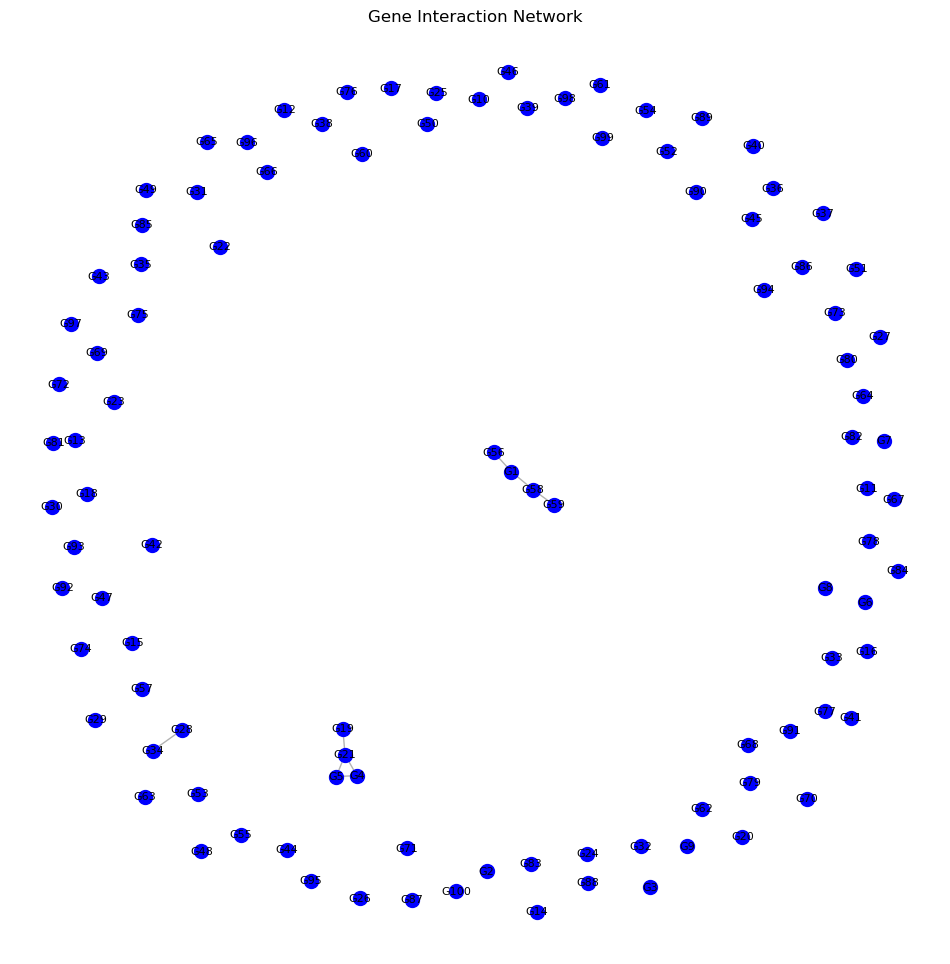

In [2412]:
import networkx as nx
import matplotlib.pyplot as plt
# Create the graph from the adjacency matrix
G = nx.from_pandas_adjacency(adj_df)
# Remove self-loops
G.remove_edges_from(nx.selfloop_edges(G))
# Draw the graph
plt.figure(figsize=(12, 12))
pos = nx.spring_layout(G, k=0.15)  # You can adjust 'k' for spacing
nx.draw_networkx_nodes(G, pos, node_size=100, node_color='blue')
nx.draw_networkx_edges(G, pos, alpha=0.3)
nx.draw_networkx_labels(G, pos, font_size=8)
plt.axis('off')
plt.title('Gene Interaction Network')
plt.show()


In [2414]:
# Number of nodes and edges
num_nodes = G.number_of_nodes()
num_edges = G.number_of_edges()
print(f"Number of nodes: {num_nodes}")
print(f"Number of edges: {num_edges}")

Number of nodes: 100
Number of edges: 8


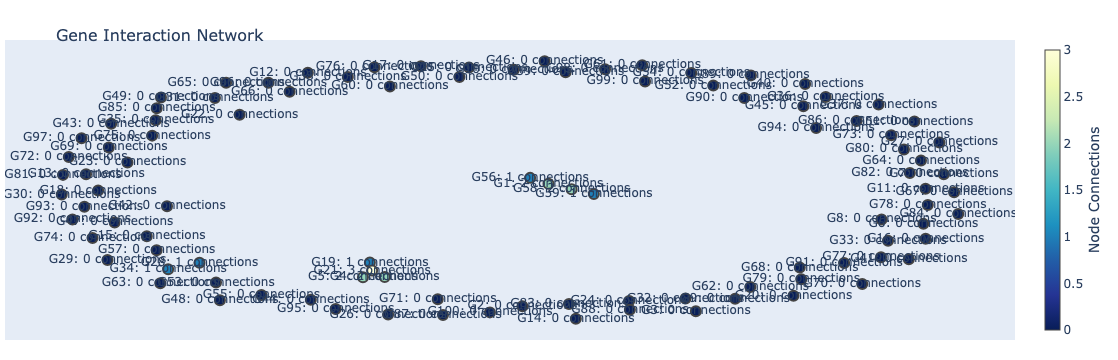

,source,target,weight
0,G1,G56,1
1,G1,G58,1
2,G19,G21,1
3,G21,G4,1
4,G21,G5,1
5,G28,G34,1
6,G4,G5,1
7,G58,G59,1


In [2416]:
import plotly.graph_objs as go
from networkx.readwrite import json_graph

# Create a Plotly figure
edge_trace = go.Scatter(
    x=[],
    y=[],
    line=dict(width=0.5, color='#888'),
    hoverinfo='none',
    mode='lines')

for edge in G.edges():
    x0, y0 = pos[edge[0]]
    x1, y1 = pos[edge[1]]
    edge_trace['x'] += (x0, x1, None)
    edge_trace['y'] += (y0, y1, None)

node_trace = go.Scatter(
    x=[],
    y=[],
    text=[],
    mode='markers+text',
    hoverinfo='text',
    marker=dict(
        showscale=True,
        colorscale='YlGnBu',
        reversescale=True,
        color=[],
        size=10,
        colorbar=dict(
            thickness=15,
            title='Node Connections',
            xanchor='left',
            titleside='right'
        ),
        line_width=2))

for node in G.nodes():
    x, y = pos[node]
    node_trace['x'] += (x,)
    node_trace['y'] += (y,)

# Color nodes by degree
node_adjacencies = []
node_text = []
for node, adjacencies in G.adjacency():
    node_adjacencies.append(len(adjacencies))
    node_text.append(f"{node}: {len(adjacencies)} connections")

node_trace.marker.color = node_adjacencies
node_trace.text = node_text

fig = go.Figure(data=[edge_trace, node_trace],
             layout=go.Layout(
                title='<br>Gene Interaction Network',
                titlefont_size=16,
                showlegend=False,
                hovermode='closest',
                margin=dict(b=20,l=5,r=5,t=40),
                annotations=[ dict(
                    text="",
                    showarrow=False,
                    xref="paper", yref="paper") ],
                xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
                yaxis=dict(showgrid=False, zeroline=False, showticklabels=False))
                )

fig.show()
# Get edge list
edge_list = nx.to_pandas_edgelist(G)
edge_list.to_csv('gene_interaction_edges.csv', index=False)
edge_list

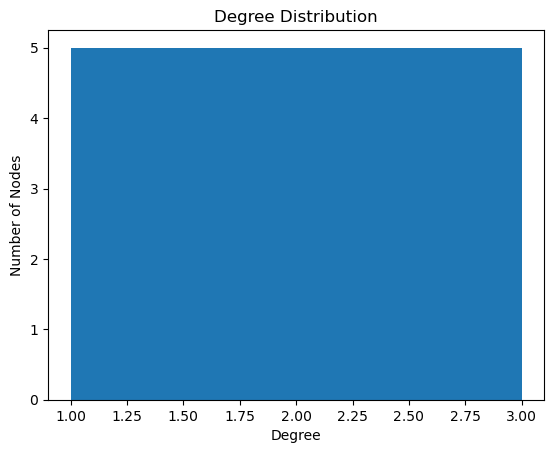

In [2418]:
# Get degrees of all nodes
degrees = dict(G.degree())
# Plot degree distribution
plt.figure()
plt.hist(degrees.values(), bins=range(1, max(degrees.values()) + 1))
plt.title('Degree Distribution')
plt.xlabel('Degree')
plt.ylabel('Number of Nodes')
plt.show()


In [2368]:
# Find nodes with highest degree (hubs)
sorted_degrees = sorted(degrees.items(), key=lambda x: x[1], reverse=True)
top_genes = sorted_degrees[:10]  # Top 10 genes
print("Top 10 genes by degree:")
for gene, degree in top_genes:
    print(f"{gene}: {degree}")


Top 10 genes by degree:
G1: 4
G19: 4
G21: 4
G56: 4
G4: 3
G5: 3
G58: 3
G50: 2
G54: 2
G59: 2


In [2497]:
import pandas as pd
import networkx as nx

# Step 1: Load known (ground truth) interactions
file_path = "/Users/nirwantandukar/input_data/Database.DREAM4/GS/dream4_100_02_gs.csv"

ground_truth = pd.read_csv(file_path, index_col=0)

# Convert ground truth matrix to edge list
def convert_matrix_to_edge_list(matrix):
    edges = []
    for source in matrix.index:
        for target in matrix.columns:
            if matrix.at[source, target] == 1:
                edges.append((source, target))
    return edges

# Get the ground truth edges
known_edges = convert_matrix_to_edge_list(ground_truth)

# Step 2: Get the predicted edges from the GRN (from your constructed GRN)
# Assume GRN is stored in a NetworkX graph `predicted_grn`
predicted_grn=G
# Convert predicted GRN to edge list
predicted_edges = list(predicted_grn.edges())

# Step 3: Compare the predicted and ground truth edges

# Convert edges to sets for easy comparison
known_edges_set = set(known_edges)
predicted_edges_set = set(predicted_edges)

# True Positives (correct predictions)
true_positives = predicted_edges_set.intersection(known_edges_set)

# False Positives (predicted edges that are not in the ground truth)
false_positives = predicted_edges_set.difference(known_edges_set)

# False Negatives (ground truth edges that are missing in the predictions)
false_negatives = known_edges_set.difference(predicted_edges_set)

# Step 4: Output the results
print(f"Number of True Positives (Correct edges): {len(true_positives)}")
print(f"Number of False Positives (Wrong edges): {len(false_positives)}")
print(f"Number of False Negatives (Missing edges): {len(false_negatives)}")

# Optional: print out the edges for further analysis
print(f"\nTrue Positive Edges:\n{true_positives}")
print(f"\nFalse Positive Edges:\n{false_positives}")
print(f"\nFalse Negative Edges:\n{false_negatives}")


Number of True Positives (Correct edges): 1
Number of False Positives (Wrong edges): 7
Number of False Negatives (Missing edges): 247

True Positive Edges:
{('G58', 'G59')}

False Positive Edges:
{('G1', 'G56'), ('G4', 'G5'), ('G21', 'G4'), ('G19', 'G21'), ('G1', 'G58'), ('G21', 'G5'), ('G28', 'G34')}

False Negative Edges:
{('G5', 'G19'), ('G79', 'G85'), ('G5', 'G1'), ('G1', 'G15'), ('G98', 'G18'), ('G29', 'G74'), ('G98', 'G7'), ('G29', 'G75'), ('G62', 'G31'), ('G53', 'G52'), ('G46', 'G37'), ('G30', 'G31'), ('G1', 'G14'), ('G29', 'G64'), ('G29', 'G76'), ('G5', 'G55'), ('G5', 'G17'), ('G64', 'G66'), ('G96', 'G63'), ('G96', 'G27'), ('G98', 'G46'), ('G80', 'G9'), ('G34', 'G36'), ('G45', 'G49'), ('G5', 'G58'), ('G36', 'G7'), ('G63', 'G27'), ('G29', 'G44'), ('G5', 'G22'), ('G23', 'G26'), ('G80', 'G61'), ('G62', 'G60'), ('G23', 'G24'), ('G80', 'G19'), ('G96', 'G97'), ('G1', 'G12'), ('G29', 'G54'), ('G80', 'G79'), ('G63', 'G97'), ('G50', 'G21'), ('G29', 'G6'), ('G29', 'G68'), ('G79', 'G15'),

In [2448]:
import torch.nn.functional as F
from torch_geometric.nn import GCNConv

# Defining the GCN Encoder with Dropout
class GCNEncoder(torch.nn.Module):
    def __init__(self, in_channels, out_channels, dropout_rate=0.5):
        super(GCNEncoder, self).__init__()
        self.conv1 = GCNConv(in_channels, 2 * out_channels, cached=False)
        self.conv2 = GCNConv(2 * out_channels, out_channels, cached=False)
        self.dropout_rate = dropout_rate  # Dropout rate

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout_rate, training=self.training)  # Applying Dropout
        x = self.conv2(x, edge_index)
        return x
# GAE model with weight decay and dropout
def apply_gae_to_adjacency(adj_matrix, node_features, embedding_dim=16, epochs=200, dropout_rate=0.5, weight_decay=1e-4):
    # Convert adjacency matrix to sparse format
    adj_sparse = sp.csr_matrix(adj_matrix)
    # Normalize the adjacency matrix
    adj_normalized = normalize_adj(adj_sparse + sp.eye(adj_sparse.shape[0]))
    # Get edge_index and edge_weight
    edge_index, edge_weight = from_scipy_sparse_matrix(adj_normalized)
    # Create data object
    x = torch.tensor(node_features, dtype=torch.float)
    data = Data(x=x, edge_index=edge_index)
    # Define model
    model = GAE(GCNEncoder(x.shape[1], embedding_dim, dropout_rate=dropout_rate))
    # Training settings
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)
    data = data.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.05, weight_decay=weight_decay)  # Applying weight decay
    # Training loop
    model.train()
    for epoch in range(1, epochs + 1):
        optimizer.zero_grad()
        z = model.encode(data.x, data.edge_index)
        loss = model.recon_loss(z, data.edge_index)
        loss.backward()
        optimizer.step()
    # After training, reconstruct adjacency matrix
    model.eval()
    with torch.no_grad():
        z = model.encode(data.x, data.edge_index)
        adj_reconstructed = model.decoder.forward_all(z).cpu().numpy()
    return adj_reconstructed


In [2450]:
import numpy as np
import pandas as pd
import networkx as nx

# Define number of iterations
num_iterations = 10
run_threshold = 8  # Number of times an edge must appear to be considered "consistent"

# Store results from multiple runs
true_positive_runs = []
false_positive_runs = []

for run in range(num_iterations):
    print(f"Processing run {run + 1}")
    
    reconstructed_adjs = []

    for alg in algorithms:
        #print(f"Processing algorithm: {alg}")
        # Extract adjacency matrix for the algorithm
        alg_columns = [col for col in data.columns if col.startswith(alg + '.')]
        alg_matrix = data[alg_columns].values
        
        # Apply GAE
        adj_reconstructed = apply_gae_to_adjacency(alg_matrix, node_features)
        
        # Binarize the reconstructed adjacency matrix
        individual_threshold = 0.8  # Adjust based on your data
        adj_binary = (adj_reconstructed > individual_threshold).astype(int)
        reconstructed_adjs.append(adj_binary)
    
    # Sum the binary adjacency matrices across algorithms
    aggregated_adj = np.sum(reconstructed_adjs, axis=0)
    adj_binary = (aggregated_adj >= 11).astype(int)
    
    # Create graph from the reconstructed adjacency matrix for this run
    adj_df = pd.DataFrame(adj_binary, index=gene_names, columns=gene_names)
    G_run = nx.from_pandas_adjacency(adj_df)
    G_run.remove_edges_from(nx.selfloop_edges(G_run))
    
    # Get the predicted edges
    predicted_edges_run = set(G_run.edges())
    
    # Get the ground truth edges
    known_edges_set = set(convert_matrix_to_edge_list(ground_truth))
    
    # Calculate true positives for this run
    true_positives_run = predicted_edges_run.intersection(known_edges_set)
    
    # Calculate false positives for this run
    false_positives_run = predicted_edges_run.difference(known_edges_set)
    
    # Store the true positives for this run
    true_positive_runs.append(true_positives_run)
    false_positive_runs.append(false_positives_run)

# Find edges that appear consistently across runs
edge_counts = {}
for edges in true_positive_runs:
    for edge in edges:
        if edge in edge_counts:
            edge_counts[edge] += 1
        else:
            edge_counts[edge] = 1

# Select edges that appear in at least the run_threshold times
consistent_edges = {edge for edge, count in edge_counts.items() if count >= run_threshold}

# Consistent False Positives across all runs
consistent_false_positives = set.intersection(*false_positive_runs)

print(f"done")
# Output the final set of consistent true positives
print(f"Consistent True Positives across runs: {len(consistent_edges)}")
print(f"Consistent True Positive Edges: {consistent_edges}")

# Consistent False Negatives across all runs
print(f"Consistent False Positives across runs: {len(consistent_false_positives)}")
print(f"Consistent False Positive Edges: {consistent_false_positives}")

Processing run 1
Processing run 2
Processing run 3
Processing run 4
Processing run 5
Processing run 6
Processing run 7
Processing run 8
Processing run 9
Processing run 10
done
Consistent True Positives across runs: 0
Consistent True Positive Edges: set()
Consistent False Positives across runs: 0
Consistent False Positive Edges: set()


In [2451]:
Consistent True Positives across runs: 13, 11
Consistent True Positive Edges: {('G10', 'G44'), ('G37', 'G48'), ('G37', 'G72'), ('G46', 'G47'), ('G72', 'G77'), ('G46', 'G53'), ('G37', 'G73'), ('G44', 'G64'), ('G43', 'G44'), ('G37', 'G74'), ('G46', 'G57'), ('G23', 'G24'), ('G37', 'G69')}
Consistent False Positives across runs: 67, 

SyntaxError: invalid syntax (223152167.py, line 1)

In [2275]:
weight decay 5
Consistent True Positives across runs: 10,11
Consistent True Positive Edges: {('G10', 'G44'), ('G37', 'G72'), ('G46', 'G47'), ('G72', 'G77'), ('G46', 'G53'), ('G44', 'G64'), ('G43', 'G44'), ('G46', 'G57'), ('G23', 'G24'), ('G37', 'G69')}
Consistent False Positives across runs: 41, 44

SyntaxError: invalid syntax (3646145608.py, line 1)

In [ ]:
weight decay 4
Consistent True Positives across runs: 11
Consistent True Positive Edges: {('G10', 'G44'), ('G37', 'G72'), ('G46', 'G47'), ('G72', 'G77'), ('G46', 'G53'), ('G37', 'G73'), ('G44', 'G64'), ('G43', 'G44'), ('G46', 'G57'), ('G23', 'G24'), ('G37', 'G69')}
Consistent False Positives across runs: 40

In [ ]:
drop out 0.4
Consistent True Positives across runs: 11
Consistent True Positive Edges: {('G10', 'G44'), ('G37', 'G72'), ('G46', 'G47'), ('G46', 'G53'), ('G72', 'G77'), ('G44', 'G64'), ('G37', 'G73'), ('G43', 'G44'), ('G46', 'G57'), ('G23', 'G24'), ('G37', 'G69')}
Consistent False Positives across runs: 47

In [2296]:
drop out 0.6
Consistent True Positives across runs: 9
Consistent True Positive Edges: {('G10', 'G44'), ('G37', 'G72'), ('G46', 'G47'), ('G72', 'G77'), ('G46', 'G53'), ('G44', 'G64'), ('G43', 'G44'), ('G46', 'G57'), ('G23', 'G24')}
Consistent False Positives across runs: 28

SyntaxError: invalid syntax (1990418530.py, line 1)

In [2306]:
so far drop ou = 0.5, weight decay = 10 e -04 

SyntaxError: leading zeros in decimal integer literals are not permitted; use an 0o prefix for octal integers (2386191901.py, line 1)

In [ ]:
learning rate 0.05
Consistent True Positives across runs: 10,9 
Consistent True Positive Edges: {('G10', 'G44'), ('G37', 'G72'), ('G46', 'G47'), ('G46', 'G53'), ('G72', 'G77'), ('G44', 'G64'), ('G43', 'G44'), ('G46', 'G57'), ('G23', 'G24'), ('G37', 'G69')}
Consistent False Positives across runs: 24,28

In [2507]:
import numpy as np
import pandas as pd
import networkx as nx

# Define number of iterations
num_iterations = 30
run_threshold = 15  # Number of times an edge must appear to be considered "consistent"

# Store true and false positives for each algorithm across multiple runs
true_positive_runs_algorithms = {alg: [] for alg in algorithms}
false_positive_runs_algorithms = {alg: [] for alg in algorithms}

# For combined data
true_positive_runs_combined = []
false_positive_runs_combined = []

for run in range(num_iterations):
    print(f"Processing run {run + 1}")
    
    reconstructed_adjs = []

    for alg in algorithms:
        # Extract adjacency matrix for the algorithm
        alg_columns = [col for col in data.columns if col.startswith(alg + '.')]
        alg_matrix = data[alg_columns].values
        
        # Apply GAE (or any model) to reconstruct the adjacency matrix for this algorithm
        adj_reconstructed = apply_gae_to_adjacency(alg_matrix, node_features)
        
        # Binarize the reconstructed adjacency matrix
        individual_threshold = 0.8  # Adjust based on your data
        adj_binary = (adj_reconstructed > individual_threshold).astype(int)
        
        # Create a graph from the reconstructed adjacency matrix for this algorithm
        adj_df = pd.DataFrame(adj_binary, index=gene_names, columns=gene_names)
        G_run = nx.from_pandas_adjacency(adj_df)
        G_run.remove_edges_from(nx.selfloop_edges(G_run))
        
        # Get the predicted edges for this run
        predicted_edges_run = set(G_run.edges())
        
        # Get the ground truth edges
        known_edges_set = set(convert_matrix_to_edge_list(ground_truth))
        
        # Calculate true positives for this run and algorithm
        true_positives_run = predicted_edges_run.intersection(known_edges_set)
        
        # Calculate false positives for this run and algorithm
        false_positives_run = predicted_edges_run.difference(known_edges_set)
        
        # Store the true positives and false positives for this run and algorithm
        true_positive_runs_algorithms[alg].append(true_positives_run)
        false_positive_runs_algorithms[alg].append(false_positives_run)
        
        # For combined data, add the adjacency binary matrix for this algorithm
        reconstructed_adjs.append(adj_binary)

    # Combine the adjacency matrices for all algorithms (for the combined data)
    aggregated_adj_combined = np.sum(reconstructed_adjs, axis=0)
    adj_binary_combined = (aggregated_adj_combined >= 8).astype(int)
    
    # Create graph from the combined adjacency matrix for this run
    adj_df_combined = pd.DataFrame(adj_binary_combined, index=gene_names, columns=gene_names)
    G_run_combined = nx.from_pandas_adjacency(adj_df_combined)
    G_run_combined.remove_edges_from(nx.selfloop_edges(G_run_combined))
    
    # Get the predicted edges for the combined run
    predicted_edges_combined = set(G_run_combined.edges())
    
    # Calculate true positives and false positives for the combined data
    true_positives_combined = predicted_edges_combined.intersection(known_edges_set)
    false_positives_combined = predicted_edges_combined.difference(known_edges_set)
    
    # Store the true and false positives for the combined run
    true_positive_runs_combined.append(true_positives_combined)
    false_positive_runs_combined.append(false_positives_combined)

# Step 2: Find consistent true and false positives across all runs for each algorithm

# Consistent True Positives and False Positives for each algorithm across all runs
consistent_true_positives_algorithms = {}
consistent_false_positives_algorithms = {}

for alg in algorithms:
    # Count the occurrences of each true positive edge across all runs
    true_edge_counts = {}
    for edges in true_positive_runs_algorithms[alg]:
        for edge in edges:
            if edge in true_edge_counts:
                true_edge_counts[edge] += 1
            else:
                true_edge_counts[edge] = 1

    # Select edges that appear in at least run_threshold times
    consistent_true_positives_algorithms[alg] = {edge for edge, count in true_edge_counts.items() if count >= run_threshold}

    # Find consistent false positives across all runs
    consistent_false_positives_algorithms[alg] = set.intersection(*false_positive_runs_algorithms[alg])

# Step 3: Find consistent true and false positives for the combined data

# Count the occurrences of each true positive edge across all runs for combined data
true_edge_counts_combined = {}
for edges in true_positive_runs_combined:
    for edge in edges:
        if edge in true_edge_counts_combined:
            true_edge_counts_combined[edge] += 1
        else:
            true_edge_counts_combined[edge] = 1

# Select edges that appear in at least run_threshold times for combined data
consistent_true_positives_combined = {edge for edge, count in true_edge_counts_combined.items() if count >= run_threshold}

# Find consistent false positives across all runs for combined data
consistent_false_positives_combined = set.intersection(*false_positive_runs_combined)

# Output the results for each algorithm
results = []

for alg in algorithms:
    results.append({
        'Algorithm': alg,
        'Consistent True Positives': len(consistent_true_positives_algorithms[alg]),
        'Consistent False Positives': len(consistent_false_positives_algorithms[alg])
    })

# Add the combined data result
results.append({
    'Algorithm': 'Combined',
    'Consistent True Positives': len(consistent_true_positives_combined),
    'Consistent False Positives': len(consistent_false_positives_combined)
})

# Step 4: Create a summary DataFrame for true and false positives
summary_table = pd.DataFrame(results)

# Display the summary table
print("\nSummary of True and False Positives for each Algorithm and Combined Data:")
print(summary_table)

# Optionally, save the table to a CSV file
summary_table.to_csv('true_false_positives_per_algorithm_and_combined.csv', index=False)
print("Summary table saved as 'true_false_positives_per_algorithm_and_combined.csv'")


Processing run 1
Processing run 2
Processing run 3
Processing run 4
Processing run 5
Processing run 6
Processing run 7
Processing run 8
Processing run 9
Processing run 10
Processing run 11
Processing run 12
Processing run 13
Processing run 14
Processing run 15
Processing run 16
Processing run 17
Processing run 18
Processing run 19
Processing run 20
Processing run 21
Processing run 22
Processing run 23
Processing run 24
Processing run 25
Processing run 26
Processing run 27
Processing run 28
Processing run 29
Processing run 30

Summary of True and False Positives for each Algorithm and Combined Data:
            Algorithm  Consistent True Positives  Consistent False Positives
0          GRN_ARACNE                         19                          55
1          GRN_BC3NET                         26                          97
2           GRN_C3NET                         14                          53
3             GRN_CLR                         23                          53
4       G

In [ ]:
17                          46